# Active Subspaces of Golinski's Speed Reducer

From: Optimal Synthesis Problems Solved by Means of Nonlinear Programming and Random Methods

__Jan Golinski__, Municipal Computer Center, Soeto, Warsaw, ul. Moliera 6, Poland

Notebook: Claude (Anthropic) for P. Constantine, 2026

### Summary

Golinski [[1]](#refs) posed the minimum-weight design of a two-gear speed reducer (gearbox) with seven design variables and solved it by crude Monte Carlo and a random "stray" search; in the form of Ray [[2]](#refs), with the number of pinion teeth held at 17, it has become a standard six-variable test problem for constrained optimization and dimension reduction [[3, 4]](#refs). We implement Golinski's own volume formula with exact constants (its rounded coefficients are the standard formulation), together with two of Ray's constraint functions for the first shaft, and estimate active subspaces from exact gradients at 1000 uniform samples on the standard design box. The volume has a dominant one-dimensional active subspace ($\lambda_1/\lambda_2 = 246.1$) on which a linear function has a leave-one-out $R^2$ of 0.996, the shaft-deflection constraint is one-dimensional with weights on shaft diameter, shaft length and module, and the shaft-stress constraint is, to $1 - |w_{1,d_1}| = 2.9\times10^{-6}$, a function of the shaft diameter $d_1$ alone.

### Active subspaces in brief

For a scalar function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the matrix $\mathbf C = \int \nabla f\,\nabla f^T \rho\, d\mathbf x = \mathbf W \Lambda \mathbf W^T$ measures how $f$ changes, on average, along each direction. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the span of the first $n$ eigenvectors $\mathbf W_1$, and $f(\mathbf x) \approx g(\mathbf W_1^T\mathbf x)$ for some function $g$ of the $n$ active variables $\mathbf y = \mathbf W_1^T\mathbf x$. $\mathbf C$ is estimated by Monte Carlo from gradient samples, and a sufficient summary plot of $f$ against $\mathbf y$ shows whether the reduction holds. See Constantine (2015) [[5]](#refs) for the theory and the algorithms used here.

### The model

**Golinski's formulation** (Sec. 3.1 of [[1]](#refs), pp. 297–299, Figs. 10–11). A single-stage reducer transmits $N = 100$ (unit printed "km", presumably the Polish KM, metric horsepower) at pinion speed $n = 1500$ min$^{-1}$ with transmission ratio $i = 3$. The seven design variables are the face width $b$, the teeth module $m_t$ (the paper's $m$), the number of pinion teeth $z$ (the wheel has $iz$), the shaft lengths between bearings $l_1, l_2$ and the shaft diameters $d_1, d_2$, all in cm. The paper lists 13 numbered conditions (tooth bending and surface stress, $z \ge 17$, $5 \le b/m_t \le 12$, overall size, shaft deflections and stresses, $d_2 \ge 5$ cm, $1.5d_1 + 1.9 \le l_1$, $1.1d_2+1.9 \le l_2$) but no box bounds.

**Volume.** With the dimensions of Fig. 11, for gear $k = 1, 2$ (teeth $z_1 = z$, $z_2 = 3z$), the root diameter $d_{st} = m_t z_k - 2.4m_t$, the inner rim diameter $d_w = d_{st} - 4m_t$ and the hub diameter $d_p = d_k + 2(0.7 d_k) = 2.4 d_k$, Golinski's objective (p. 299) is the volume of the two gear blanks (rim of width $b$, web of width $b/3$, hub of length $2d_k$) and the two shafts:
$$V = \sum_{k=1}^2\Big[(d_{st}^2 - d_w^2)\frac{\pi b}{4} + (d_w^2-d_p^2)\frac{\pi b}{12} + (d_p^2-d_k^2)\frac{\pi}{4}2d_k\Big] + \frac{\pi}{4}\sum_{k=1}^2 d_k^2 l_k .$$
The scanned formula prints the hub factor as "$2b$" and the shaft term with $d_k$ in place of $d_k^2$; we read both from Fig. 11 (hub length $2d_k$) and from dimensional consistency. Expanded,
$$V = \tfrac{\pi}{4} b m_t^2\big(\tfrac{10}{3}z^2 + \tfrac{224}{15}z - \tfrac{646.4}{15}\big) - 0.48\pi\, b(d_1^2+d_2^2) + 2.38\pi(d_1^3+d_2^3) + \tfrac{\pi}{4}(l_1d_1^2 + l_2d_2^2),$$
and rounding these coefficients to 0.7854, 3.3333, 14.9334, 43.0934, 1.508 and 7.477 gives exactly the **standard formulation** of Ray [[2]](#refs), the NASA Langley MDO test suite and psdr [[4]](#refs). So the standard volume *is* Golinski's, with rounded constants; we use the exact constants (the two differ by at most a relative $1.5\times10^{-6}$ on our samples, checked below).

**Constraints.** Golinski's constraint formulas use constants he does not print (the elastic coefficient $B$, Young's modulus, the moments), so we take the constraint functions from Ray [[2]](#refs) as printed in psdr [[4]](#refs), each scaled to be satisfied when $\le 0$. We use two of Ray's eleven, both for shaft 1; each is smooth and depends on three inputs:
$$g_3 = \frac{1.93\, l_1^3}{m_t z d_1^4} - 1 \quad\text{(deflection of shaft 1, Golinski's condition 7)},\qquad g_5 = \frac{\sqrt{(745\, l_1/(m_t z))^2 + 16.9\times10^6}}{110\, d_1^3} - 1 \quad\text{(substitute stress in shaft 1, condition 9)}.$$
The other nine are monomials or ratios in $(b, m_t)$ (tooth bending and surface stress, overall size, the face-width ratio), the design conditions $(1.5d_1+1.9)/l_1 - 1$ and $(1.1d_2+1.9)/l_2 - 1$, and the shaft-2 analogues of $g_3$ and $g_5$.

**Held input.** $z$ is an integer; we hold it at $z = 17$, the lower limit of Golinski's condition 3 and the value of both the standard formulation and his crude Monte Carlo optimum (Table 1). So $m = 6$.

**Input space.** Independent uniforms on the box of psdr's `build_golinski_design_domain` [[4]](#refs), which follows Ray [[2]](#refs) (the paper has no box). Other sources give $l_2 \in [7.8, 8.4]$ instead of $[7.3, 8.3]$; we check below that this does not change the result.

**Quantities of interest:** $V$ (cm$^3$), $g_3$ and $g_5$ (dimensionless). **Gradients:** exact, by differentiating the closed forms (`golinski_model.py`), with respect to the physical inputs.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import active_subspaces as ac
import golinski_model as gm

SEED = 1970   # every rng= below uses this seed
t_start = time.perf_counter()

labels = [r'$b$', r'$m_t$', r'$l_1$', r'$l_2$', r'$d_1$', r'$d_2$']
qoi_labels = [r'$V$ (cm$^3$)', r'$g_3$', r'$g_5$']
print(f'z = {gm.Z} (held), transmission ratio i = {gm.RATIO}')
print(f"{'input':6s} {'description':34s} {'unit':5s} {'lower':>6s} {'upper':>6s}  source")
for j, name in enumerate(gm.NAMES):
    print(f'{name:6s} {gm.DESCRIPTIONS[j]:34s} {gm.UNITS[j]:5s} {gm.LOWER[j]:6.2f} {gm.UPPER[j]:6.2f}  '
          'psdr build_golinski_design_domain (after Ray 2003)')

z = 17 (held), transmission ratio i = 3
input  description                        unit   lower  upper  source
b      face width                         cm      2.60   3.60  psdr build_golinski_design_domain (after Ray 2003)
m_t    teeth module                       cm      0.70   0.80  psdr build_golinski_design_domain (after Ray 2003)
l1     shaft 1 length between bearings    cm      7.30   8.30  psdr build_golinski_design_domain (after Ray 2003)
l2     shaft 2 length between bearings    cm      7.30   8.30  psdr build_golinski_design_domain (after Ray 2003)
d1     shaft 1 diameter                   cm      2.90   3.90  psdr build_golinski_design_domain (after Ray 2003)
d2     shaft 2 diameter                   cm      5.00   5.50  psdr build_golinski_design_domain (after Ray 2003)


### Load the data

`generate_data.py` drew 1000 uniform samples on the box (seed 1970) and evaluated $V$, $g_3$, $g_5$ and their exact gradients with respect to the physical inputs (`DATA.md`; the run takes a few milliseconds).

In [2]:
X = np.loadtxt('inputs.csv', delimiter=',')                          # (1000, 6) physical inputs, cm
F = np.loadtxt('outputs.csv', delimiter=',')                         # (1000, 3) V, g3, g5
G = np.loadtxt('gradients.csv', delimiter=',').reshape(len(X), 3, 6)  # d(output)/d(physical input)
print(f'inputs {X.shape}, outputs {F.shape}, gradients {G.shape}')

inputs (1000, 6), outputs (1000, 3), gradients (1000, 3, 6)


Checks: the model reproduces the stored outputs; the expanded volume agrees with the term-by-term geometric sum of Fig. 11 and with the rounded standard coefficients; the exact gradients agree with central finite differences (step $10^{-6}$ times the range) on 50 samples.

In [3]:
print(f'model vs outputs.csv: max relative difference {np.max(np.abs(gm.qoi(X) - F) / np.abs(F)):.1e}')
print(f'expanded vs geometric volume: max relative difference '
      f'{np.max(np.abs(gm.volume(X) - gm.volume_geometric(X)) / F[:, 0]):.1e}')
print(f'exact vs rounded standard coefficients: max relative difference '
      f'{np.max(np.abs(gm.volume(X) - gm.volume_rounded(X)) / F[:, 0]):.1e}')
Xc = X[:50]
Gfd = np.empty((50, 3, 6))
for j in range(6):
    dx = np.zeros(6)
    dx[j] = 1e-6 * (gm.UPPER[j] - gm.LOWER[j])
    Gfd[:, :, j] = (gm.qoi(Xc + dx) - gm.qoi(Xc - dx)) / (2 * dx[j])
rel = np.linalg.norm(Gfd - G[:50], axis=2) / np.linalg.norm(G[:50], axis=2)
print('central differences vs stored gradients, max relative error (V, g3, g5):',
      ', '.join(f'{r:.1e}' for r in rel.max(0)))
print(f'V: min {F[:, 0].min():.1f}, mean {F[:, 0].mean():.1f}, max {F[:, 0].max():.1f} cm^3; '
      f'feasible fraction: g3 <= 0 {np.mean(F[:, 1] <= 0):.3f}, g5 <= 0 {np.mean(F[:, 2] <= 0):.3f}')

model vs outputs.csv: max relative difference 1.3e-13
expanded vs geometric volume: max relative difference 6.0e-16
exact vs rounded standard coefficients: max relative difference 1.5e-06
central differences vs stored gradients, max relative error (V, g3, g5): 1.6e-09, 1.6e-09, 1.5e-09
V: min 2482.3, mean 3043.6, max 3659.4 cm^3; feasible fraction: g3 <= 0 0.941, g5 <= 0 0.530


### Estimate the active subspaces

The gradients are exact, so we use the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1N\sum_i \nabla f(\mathbf x_i)\nabla f(\mathbf x_i)^T$, with 500 bootstrap replicates. The input space is `ac.Uniform(LOWER, UPPER)`, whose normalization maps the box to $[-1, 1]^6$; v1 maps the physical gradients to $\partial f/\partial x_j = \tfrac12(u_j - \ell_j)\,\partial f/\partial \xi_j$. We orient each $\mathbf w_1$ so that the output increases along it, and choose $n$ by the eigenvalue-gap rule.

In [4]:
space = ac.Uniform(gm.LOWER, gm.UPPER, names=list(gm.NAMES))
subs = []
for i, q in enumerate(gm.QOI_NAMES):
    sub = ac.active_subspace(space=space, X=X, f=F[:, i], grads=G[:, i], estimator='as',
                             nboot=500, bootstrap_vectors=2, rng=SEED, qoi=q)
    sub = ac.orient(sub, by='covariance', X=X, f=F[:, i], columns=2)
    subs.append(sub)


def top(w, k=4):
    return ', '.join(f'{gm.NAMES[j]} {w[j]:+.3f}' for j in np.argsort(-np.abs(w))[:k])


for i, (q, sub) in enumerate(zip(gm.QOI_NAMES, subs)):
    lam = sub.eigenvalues
    print(f'{q}: n = {sub.n} (eigenvalue-gap rule); eigenvalues = '
          + ', '.join(f'{v:.3e}' for v in lam)
          + f'; lambda_1/lambda_2 = {lam[0] / lam[1]:.4g}, lambda_2/lambda_3 = {lam[1] / lam[2]:.4g}')
    d = sub.bootstrap_distances.mean(0)
    lo, hi = np.percentile(sub.bootstrap_eigenvalues[:, 0], [2.5, 97.5])
    print(f'    lambda_1 bootstrap 95% interval [{lo:.4e}, {hi:.4e}]; '
          f'mean bootstrap subspace distance n = 1: {d[0]:.1e}, n = 2: {d[1]:.1e}')
    print(f'    w1: {top(sub.W[:, 0], 6)}')
    print(f'    w2: {top(sub.W[:, 1], 6)}')

volume: n = 1 (eigenvalue-gap rule); eigenvalues = 1.424e+05, 5.785e+02, 2.629e+02, 1.638e+02, 2.155e-03, 8.510e-04; lambda_1/lambda_2 = 246.1, lambda_2/lambda_3 = 2.2
    lambda_1 bootstrap 95% interval [1.4147e+05, 1.4333e+05]; mean bootstrap subspace distance n = 1: 2.4e-03, n = 2: 3.4e-02
    w1: b +0.610, m_t +0.570, d2 +0.419, d1 +0.356, l2 +0.029, l1 +0.012
    w2: d1 -0.881, m_t +0.399, b +0.223, d2 -0.120, l1 -0.029, l2 -0.007
g3: n = 1 (eigenvalue-gap rule); eigenvalues = 1.762e-01, 1.028e-04, 4.307e-06, 1.423e-40, 0.000e+00, 0.000e+00; lambda_1/lambda_2 = 1714, lambda_2/lambda_3 = 23.87
    lambda_1 bootstrap 95% interval [1.6612e-01, 1.8642e-01]; mean bootstrap subspace distance n = 1: 7.6e-04, n = 2: 5.7e-03
    w1: d1 -0.952, l1 +0.288, m_t -0.101, b +0.000, l2 +0.000, d2 +0.000
    w2: l1 +0.917, d1 +0.304, m_t -0.259, b -0.000, l2 -0.000, d2 -0.000
g5: n = 1 (eigenvalue-gap rule); eigenvalues = 2.406e-01, 2.691e-08, 3.876e-10, 1.761e-44, 0.000e+00, 0.000e+00; lambda_1/l

### Results

#### Volume $V$

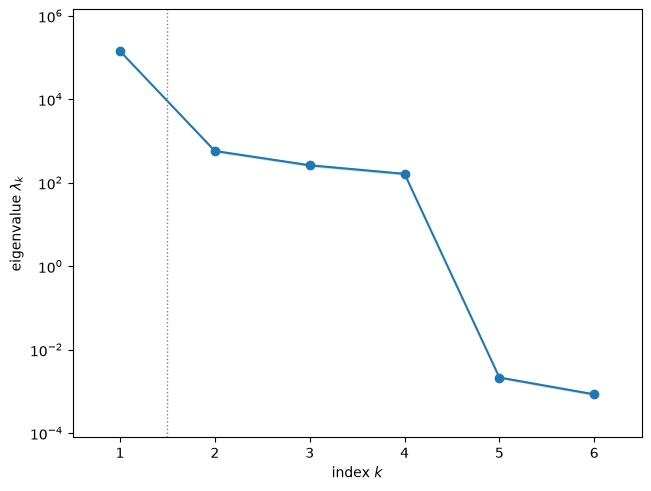

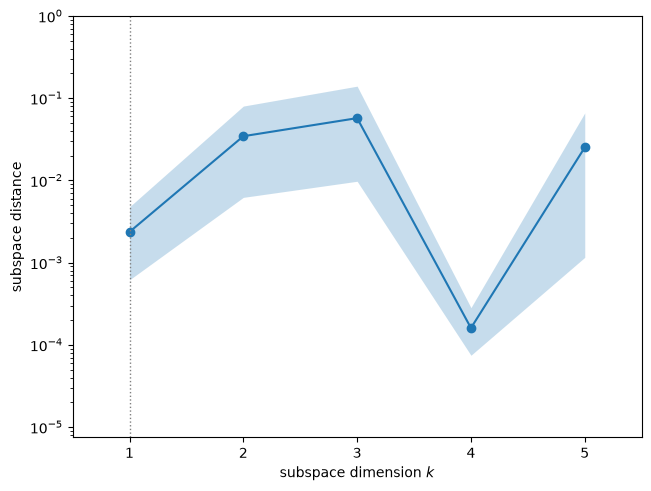

In [5]:
sub = subs[0]
display(ac.plotting.plot_eigenvalues(sub)[0])
display(ac.plotting.plot_subspace_errors(sub)[0])

The eigenvalues of $\hat{\mathbf C}$ for the volume are $1.424\times10^{5}$, $578.5$, $262.9$, $163.8$, $2.2\times10^{-3}$ and $8.5\times10^{-4}$: the first is 246.1 times the second, and the next three are within a factor of 3.6 of each other ($\lambda_2/\lambda_3 = 2.2$). The eigenvalue-gap rule picks $n = 1$; the bootstrap 95% interval for $\lambda_1$ is $[1.4147, 1.4333]\times10^{5}$, and the mean bootstrap subspace distance is $2.4\times10^{-3}$ for $n = 1$ against $3.4\times10^{-2}$ for $n = 2$, so the one-dimensional subspace is well determined and the second direction less so.

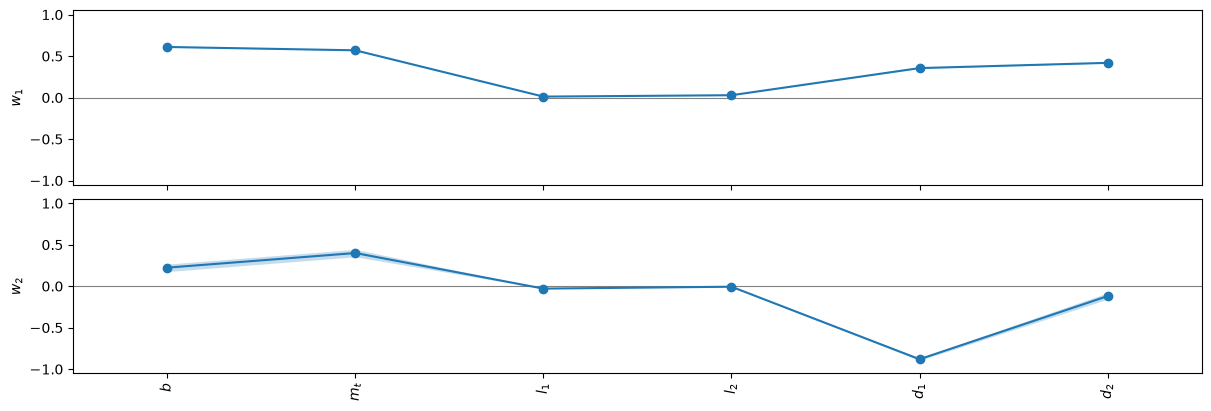

In [6]:
fig, _ = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels, interval='percentile', figsize=(12, 4))
fig

The first eigenvector weights the face width $b$ (+0.610) and the module $m_t$ (+0.570), then the shaft diameters $d_2$ (+0.419) and $d_1$ (+0.356); the shaft lengths hardly enter ($l_2$ +0.029, $l_1$ +0.012). The gears' rim and web volume $\tfrac{\pi}{4}bm_t^2(\dots)$ is on average 52.8% of $V$ (printed below), and $b$ and $m_t$ carry 37.1% and 32.4% of the mean squared normalized gradient, $d_2$ and $d_1$ 17.5% and 12.9% (through the hub term $2.38\pi d_k^3$), and $l_1, l_2$ together 0.1%. The second eigenvector is mostly $d_1$ (−0.881) against $m_t$ (+0.399) and $b$ (+0.223).

share of E[(dV/dx_j)^2] by input: b 0.371, m_t 0.324, l1 0.000, l2 0.001, d1 0.129, d2 0.175
gear rim + web term (pi/4) b m_t^2 c(z): mean 1609.9 cm^3 (52.8% of V on average)


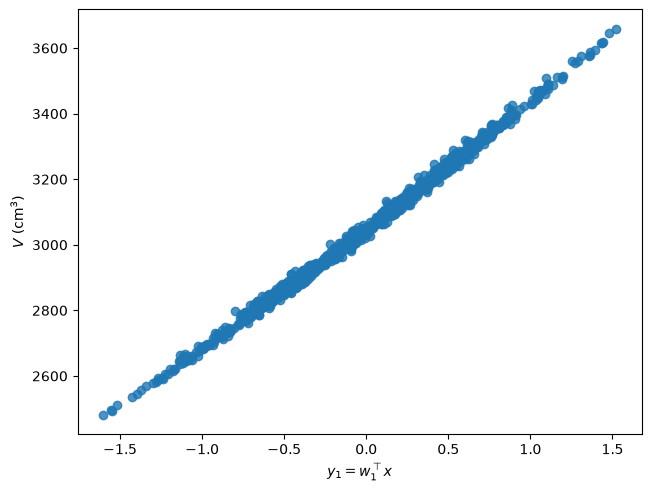

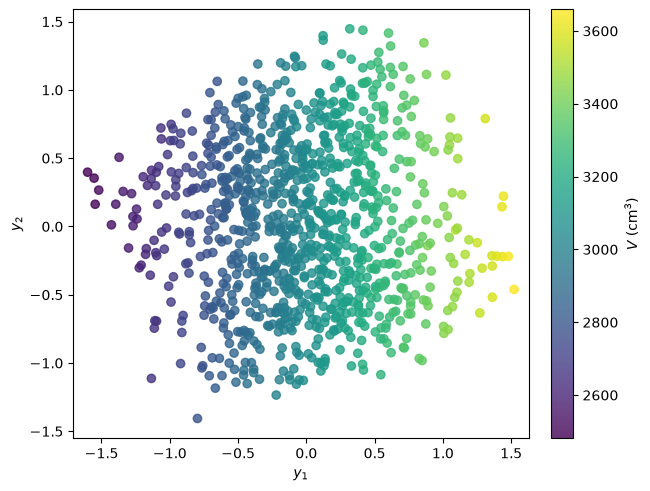

In [7]:
# Share of the mean squared normalized gradient carried by each term group of V
h = 0.5 * (gm.UPPER - gm.LOWER)
Gn = G[:, 0] * h
share = np.mean(Gn**2, axis=0) / np.sum(np.mean(Gn**2, axis=0))
print('share of E[(dV/dx_j)^2] by input:', ', '.join(f'{n} {s:.3f}' for n, s in zip(gm.NAMES, share)))
gear = np.pi / 4 * X[:, 0] * X[:, 1]**2 * gm._zpoly(gm.Z, gm.RATIO)
print(f'gear rim + web term (pi/4) b m_t^2 c(z): mean {gear.mean():.1f} cm^3 '
      f'({np.mean(gear / F[:, 0]):.1%} of V on average)')
display(ac.plotting.plot_sufficient_summary(sub, X=X, f=F[:, 0], dims=1, qoi_label=qoi_labels[0])[0])
display(ac.plotting.plot_sufficient_summary(ac.with_dimension(sub, 2), X=X, f=F[:, 0], dims=2,
                                            qoi_label=qoi_labels[0])[0])

The one-dimensional summary plot is a thin, nearly straight band from about 2480 to 3660 cm$^3$ (the sample range is 2482.3 to 3659.4 cm$^3$, mean 3043.6): the volume is close to a linear function of $y_1$ over this box. A linear fit in $y_1$ has a leave-one-out $R^2$ of 0.996047 and a quadratic 0.997039; the spread at fixed $y_1$ is along $y_2$, and a quadratic in $(y_1, y_2)$ reaches 0.998513 (surrogates below).

#### Shaft 1 deflection constraint $g_3$

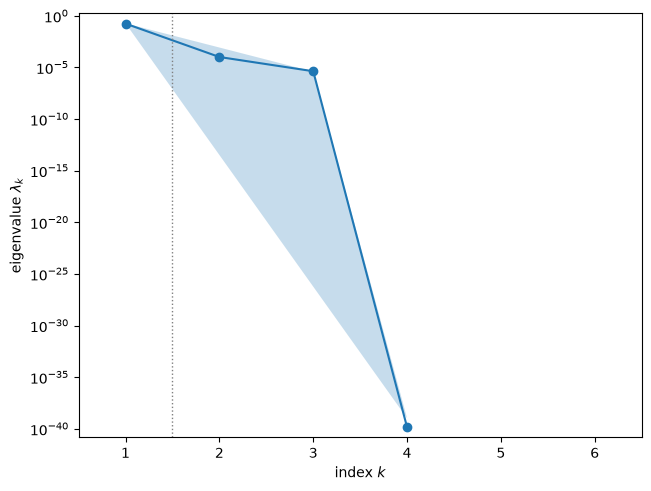

monomial direction at the centre: d1 -0.945, l1 +0.309, m_t -0.107; |w1 . ref| = 0.9997


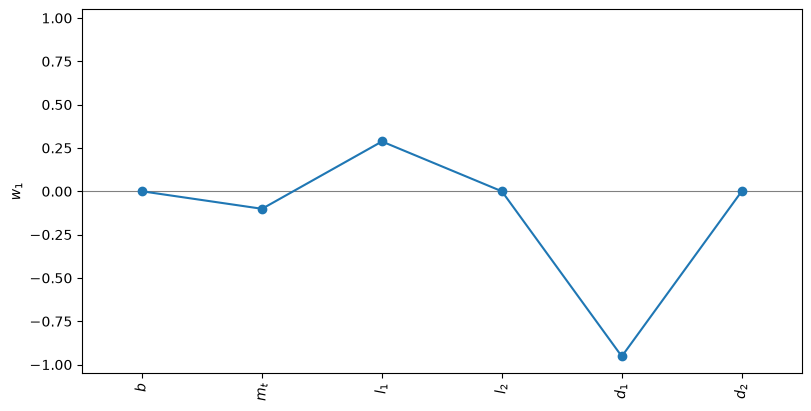

In [8]:
sub = subs[1]
display(ac.plotting.plot_eigenvalues(sub)[0])
# g3 is a monomial: log(g3 + 1) is linear in log inputs, with exponents (0, -1, 3, 0, -4, 0).
# Its gradient direction at the box centre, in normalized coordinates:
c = gm.NOMINAL
ref = np.array([0, -1, 3, 0, -4, 0]) / c * h
ref /= np.linalg.norm(ref)
print(f'monomial direction at the centre: {top(ref, 3)}; |w1 . ref| = {abs(sub.W[:, 0] @ ref):.4f}')
fig, _ = ac.plotting.plot_eigenvectors(sub, indices=[0], labels=labels, interval='percentile', figsize=(8, 4))
fig

For the shaft-1 deflection constraint $g_3$, $\lambda_1 = 0.1762$ and $\lambda_2 = 1.028\times10^{-4}$ ($\lambda_1/\lambda_2 = 1714$, $\lambda_2/\lambda_3 = 23.87$); the last three eigenvalues are zero because $g_3$ does not depend on $b$, $l_2$ or $d_2$ (the gradient columns are exactly zero; $\lambda_4$ prints as a rounding error of order $10^{-40}$, $\lambda_5$ and $\lambda_6$ as 0). The rule picks $n = 1$ (bootstrap interval for $\lambda_1$: $[0.16612, 0.18642]$; mean subspace distance $7.6\times10^{-4}$). The first eigenvector is $d_1$ −0.952, $l_1$ +0.288, $m_t$ −0.101: a thicker shaft lowers the deflection, a longer one raises it. Since $g_3 + 1 = 1.93\,l_1^3/(m_tzd_1^4)$ is a monomial, its gradient direction at the box centre, with normalized slopes proportional to the exponents $(-1, 3, -4)$ times half-range over value, is $d_1$ −0.945, $l_1$ +0.309, $m_t$ −0.107, and agrees with $\mathbf w_1$ to $|\mathbf w_1\cdot\text{ref}| = 0.9997$.

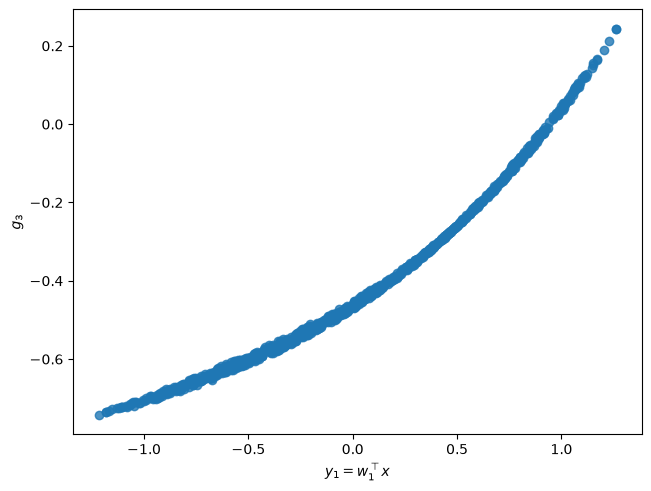

In [9]:
fig, _ = ac.plotting.plot_sufficient_summary(sub, X=X, f=F[:, 1], dims=1, qoi_label=qoi_labels[1])
fig

The summary plot is a thin convex curve: $g_3$ is a monotone function of $y_1$, and the feasibility boundary $g_3 = 0$ cuts the curve near its upper end (94.1% of the samples are feasible). A cubic in $y_1$ has a leave-one-out $R^2$ of 0.999516 (linear 0.952913, quadratic 0.998063).

#### Shaft 1 stress constraint $g_5$

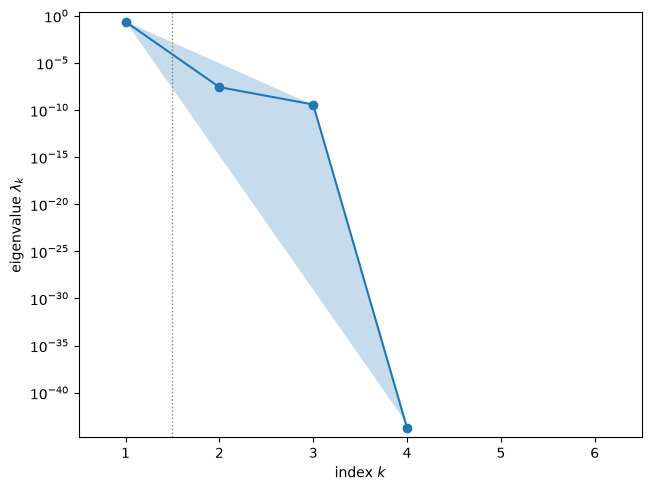

bending-moment term (745 l1/(m_t z))^2 / 16.9e6: min 0.0096, max 0.0157
1 - |w1 component of d1| = 2.9e-06
g5 = 0 at d1 = 3.3486 cm for l1 = 7.3, m_t = 0.8
g5 = 0 at d1 = 3.3522 cm for l1 = 8.3, m_t = 0.7


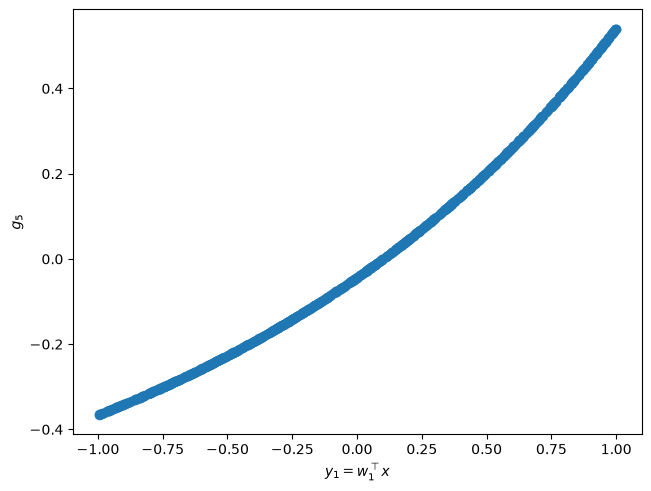

In [10]:
sub = subs[2]
display(ac.plotting.plot_eigenvalues(sub)[0])
t = 745 * X[:, 2] / (X[:, 1] * gm.Z)
print(f'bending-moment term (745 l1/(m_t z))^2 / 16.9e6: min {np.min(t**2 / 16.9e6):.4f}, max {np.max(t**2 / 16.9e6):.4f}')
print(f'1 - |w1 component of d1| = {1 - abs(sub.W[4, 0]):.1e}')
# Feasibility boundary g5 = 0 in d1, for the extremes of l1/m_t in the box
for l1, mt in [(gm.LOWER[2], gm.UPPER[1]), (gm.UPPER[2], gm.LOWER[1])]:
    d1_star = (np.sqrt((745 * l1 / (mt * gm.Z))**2 + 16.9e6) / 110)**(1 / 3)
    print(f'g5 = 0 at d1 = {d1_star:.4f} cm for l1 = {l1}, m_t = {mt}')
fig, _ = ac.plotting.plot_sufficient_summary(sub, X=X, f=F[:, 2], dims=1, qoi_label=qoi_labels[2])
fig

For the shaft-1 stress constraint $g_5$ the gap is extreme: $\lambda_1 = 0.2406$ and $\lambda_2 = 2.691\times10^{-8}$, so $\lambda_1/\lambda_2 = 8.939\times10^{6}$, and the first eigenvector is the shaft diameter alone ($d_1$ −1.000, with $1 - |w_{1,d_1}| = 2.9\times10^{-6}$; $m_t$ −0.002, $l_1$ +0.002). The reason is in the formula: under the square root the bending term $(745\,l_1/(m_tz))^2$ is between 0.0096 and 0.0157 of the torsion term $16.9\times10^6$ on this box, so $g_5 \approx 4111/(110\,d_1^3) - 1$. The constraint is active inside the box (53.0% of the samples are feasible), and its boundary $g_5 = 0$ is the plane $d_1 \approx 3.35$ cm (3.3486 to 3.3522 cm at the extremes of $l_1/m_t$). The summary plot is a single smooth curve, and a cubic in $y_1$ has a leave-one-out $R^2$ of 0.999996.

### Surrogates on the active variables

Polynomial surrogates $g(\mathbf W_1^T\mathbf x)$ on one and two active variables, with leave-one-out $R^2$.

volume: n = 1, degree 1: LOO R^2 = 0.996047
volume: n = 1, degree 2: LOO R^2 = 0.997039
volume: n = 1, degree 3: LOO R^2 = 0.997035
volume: n = 2, degree 1: LOO R^2 = 0.996054
volume: n = 2, degree 2: LOO R^2 = 0.998513
volume: n = 2, degree 3: LOO R^2 = 0.998504
g3: n = 1, degree 1: LOO R^2 = 0.952913
g3: n = 1, degree 2: LOO R^2 = 0.998063
g3: n = 1, degree 3: LOO R^2 = 0.999516
g3: n = 2, degree 1: LOO R^2 = 0.954034
g3: n = 2, degree 2: LOO R^2 = 0.998807
g3: n = 2, degree 3: LOO R^2 = 0.999960
g5: n = 1, degree 1: LOO R^2 = 0.976718
g5: n = 1, degree 2: LOO R^2 = 0.999643
g5: n = 1, degree 3: LOO R^2 = 0.999996
g5: n = 2, degree 1: LOO R^2 = 0.976673
g5: n = 2, degree 2: LOO R^2 = 0.999642
g5: n = 2, degree 3: LOO R^2 = 0.999995


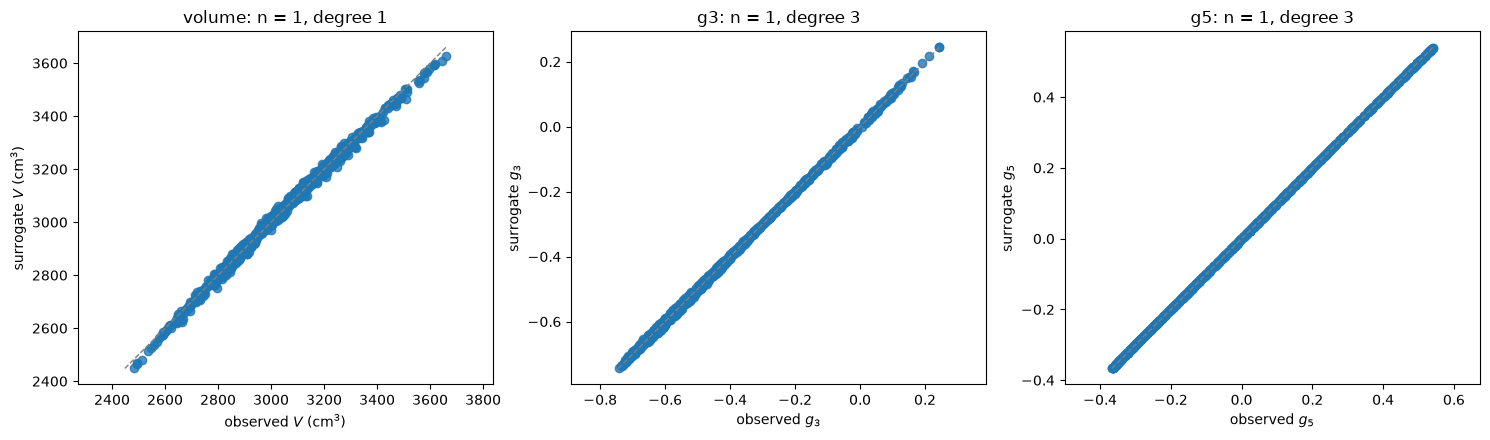

In [11]:
fits = {}
for i, q in enumerate(gm.QOI_NAMES):
    for n in [1, 2]:
        for deg in [1, 2, 3]:
            s = ac.fit_surrogate(X=X, f=F[:, i], space=space, subspace=ac.with_dimension(subs[i], n),
                                 kind='poly', degree=deg)
            fits[q, n, deg] = s
            print(f'{q}: n = {n}, degree {deg}: LOO R^2 = {s.loo_r_squared:.6f}')
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (i, n, deg) in zip(axes, [(0, 1, 1), (1, 1, 3), (2, 1, 3)]):
    ac.plotting.plot_surrogate_fit(fits[gm.QOI_NAMES[i], n, deg], X=X, f=F[:, i], qoi_label=qoi_labels[i], ax=ax)
    ax.set_title(f'{gm.QOI_NAMES[i]}: n = {n}, degree {deg}')
fig.tight_layout()
plt.close(fig)
fig

One active variable is enough for all three outputs: a linear function of $y_1$ gives $R^2 = 0.996047$ for the volume, and cubics give 0.999516 for $g_3$ and 0.999996 for $g_5$. A second active variable helps the volume a little (quadratic in $(y_1, y_2)$: 0.998513, against 0.997039 for a quadratic in $y_1$) and $g_3$ a little (cubic: 0.999960), and $g_5$ not at all (0.999995).

### Sensitivity to the box and to the rounded coefficients

Two choices are not from Golinski: the box, and (in the standard formulation) the rounded coefficients. We redraw 1000 samples (seed `SEED`) with $l_2 \in [7.8, 8.4]$, the alternative bound quoted in other sources, and compare the first eigenvectors; we also estimate the subspace of the rounded-coefficient volume on the shipped samples (by central differences, since only the exact gradient is coded).

In [12]:
lo_alt, up_alt = gm.LOWER.copy(), gm.UPPER.copy()
lo_alt[3], up_alt[3] = 7.8, 8.4
X_alt = gm.sample(1000, SEED, lower=lo_alt, upper=up_alt)
F_alt, G_alt = gm.qoi(X_alt), gm.grad(X_alt)
space_alt = ac.Uniform(lo_alt, up_alt, names=list(gm.NAMES))
for i, q in enumerate(gm.QOI_NAMES):
    s_alt = ac.active_subspace(space=space_alt, X=X_alt, f=F_alt[:, i], grads=G_alt[:, i])
    lam = s_alt.eigenvalues
    print(f'{q}: l2 in [7.8, 8.4] gives lambda_1/lambda_2 = {lam[0] / lam[1]:.4g}, n = {s_alt.n}; '
          f'|w1 . w1\'| = {abs(subs[i].W[:, 0] @ s_alt.W[:, 0]):.5f}')

G_round = np.empty((len(X), 6))
for j in range(6):
    dx = np.zeros(6)
    dx[j] = 1e-6 * (gm.UPPER[j] - gm.LOWER[j])
    G_round[:, j] = (gm.volume_rounded(X + dx) - gm.volume_rounded(X - dx)) / (2 * dx[j])
s_round = ac.active_subspace(space=space, X=X, f=gm.volume_rounded(X), grads=G_round)
print(f'rounded-coefficient volume: lambda_1/lambda_2 = {s_round.eigenvalues[0] / s_round.eigenvalues[1]:.4g}; '
      f'|w1 . w1(exact)| = {abs(subs[0].W[:, 0] @ s_round.W[:, 0]):.7f}')

volume: l2 in [7.8, 8.4] gives lambda_1/lambda_2 = 246.4, n = 1; |w1 . w1'| = 0.99993
g3: l2 in [7.8, 8.4] gives lambda_1/lambda_2 = 1714, n = 1; |w1 . w1'| = 1.00000
g5: l2 in [7.8, 8.4] gives lambda_1/lambda_2 = 8.939e+06, n = 1; |w1 . w1'| = 1.00000
rounded-coefficient volume: lambda_1/lambda_2 = 246.1; |w1 . w1(exact)| = 1.0000000


Neither choice matters. With $l_2 \in [7.8, 8.4]$ the first eigenvectors agree with those above to $|\mathbf w_1\cdot\mathbf w_1'| = 0.99993$ (volume) and 1.00000 ($g_3$, $g_5$, which do not depend on $l_2$), and the volume's $\lambda_1/\lambda_2$ is 246.4 instead of 246.1. The rounded-coefficient volume of the standard formulation has $\lambda_1/\lambda_2 = 246.1$ and the same first eigenvector to $|\mathbf w_1\cdot\mathbf w_1| = 1.0000000$.

### Comparison with the paper

Golinski reports no parameter study, only two optimized designs (Table 1, p. 300) with their objective values. We evaluate our volume at those designs (both lie partly outside the standard box; the second has $z = 18$).

In [13]:
table1 = {'crude Monte Carlo': ([4.4, 0.6, 7.3, 8.1, 3.4, 5.0], 17, 2236.35),
          'stray process': ([3.6, 0.7, 6.6, 8.2, 2.8, 5.2], 18, 2247.79)}
for k, (x, z, f_paper) in table1.items():
    x = np.array(x)
    v = gm.volume(x, z=z)
    print(f'{k:18s} z = {z}: paper f = {f_paper:8.2f} cm^3, our V = {v:8.2f} cm^3 ({v / f_paper - 1:+.1%}); '
          f'g3 = {gm.g3(x, z=z):+.3f}, g5 = {gm.g5(x, z=z):+.3f}; '
          f'inside the box: {bool(np.all((x >= gm.LOWER) & (x <= gm.UPPER)))}')
print(f'V at the box centre: {gm.volume(gm.NOMINAL):.2f} cm^3')

crude Monte Carlo  z = 17: paper f =  2236.35 cm^3, our V =  2671.92 cm^3 (+19.5%); g3 = -0.449, g5 = -0.041; inside the box: False
stray process      z = 18: paper f =  2247.79 cm^3, our V =  3049.87 cm^3 (+35.7%); g3 = -0.284, g5 = +0.710; inside the box: False
V at the box centre: 3040.59 cm^3


| quantity | paper value | notebook value |
|---|---|---|
| objective at the crude Monte Carlo design, $z = 17$ (cm$^3$) | 2236.35 (Table 1) | 2671.92 (+19.5%) |
| objective at the stray-process design, $z = 18$ (cm$^3$) | 2247.79 (Table 1) | 3049.87 (+35.7%) |
| number of design variables | 7 ($z$ integer) | 6 ($z = 17$ held) |
| box for the inputs | not reported | psdr / Ray (2003) box |
| active subspace dimension $n$ ($V$, $g_3$, $g_5$) | not reported | 1, 1, 1 |
| $\lambda_1/\lambda_2$ ($V$, $g_3$, $g_5$) | not reported | 246.1, 1714, $8.939\times10^{6}$ |
| leading inputs of $\mathbf w_1$ for $V$ | not reported | $b$, $m_t$, $d_2$, $d_1$ |
| ridge / Lipschitz-matrix results for the 6-D volume (Hokanson and Constantine [[3]](#refs)) | not reported in [1]; not checked here | — |

The paper's own numbers are not reproduced. Our volume at Golinski's two optimized designs is 2671.92 and 3049.87 cm$^3$, against 2236.35 and 2247.79 cm$^3$ in his Table 1: the two printed values differ by 0.5% while ours differ by 14%, so no constant factor (e.g. a density or a unit) explains the gap. We also tried the formula exactly as scanned ("$2b$" for the hub factor, $d_k$ for $d_k^2$) and several other readings of the hub term; none gives both Table 1 values (`DATA.md`). Since the expanded form of our reading reproduces every coefficient of the standard formulation, we believe the reading is right and that Table 1 used a computation or design values that differ from what is printed. The paper reports no sensitivity or dimension reduction results. Hokanson and Constantine [[3]](#refs) and psdr [[4]](#refs) study the same six-input standard volume (psdr's box, $z = 17$); we did not have their numbers to compare.

In [14]:
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

Total run time: 6 s


<a id="refs"></a>
### References

[1] J. Golinski, Optimal synthesis problems solved by means of nonlinear programming and random methods, *Journal of Mechanisms* 5(3):287–309, 1970. [doi:10.1016/0022-2569(70)90064-9](https://doi.org/10.1016/0022-2569(70)90064-9)

[2] T. Ray, Golinski's speed reducer problem revisited, *AIAA Journal* 41(3):556–558, 2003. [doi:10.2514/2.1984](https://doi.org/10.2514/2.1984)

[3] J. M. Hokanson and P. G. Constantine, The Lipschitz matrix: a tool for parameter space dimension reduction, *SIAM Journal on Scientific Computing*. [doi:10.1137/20M1364850](https://doi.org/10.1137/20M1364850)

[4] J. M. Hokanson, psdr: parameter space dimension reduction (Python package), `psdr/demos/golinski.py`, <https://github.com/jeffrey-hokanson/PSDR>; documentation <https://psdr.readthedocs.io/en/latest/demos.html>.

[5] P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)